In [1]:
# ─────────────────────────────────────────────────────────────────────────────
# Standard Library Imports

# ─────────────────────────────────────────────────────────────────────────────
# Third-Party Imports
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy.stats import ks_2samp
from pathlib import Path
from typing import List

# Define Seaborn style
def set_academic_style():
    
    # Color Universal Design Palette
    color_palette = [
        "#377eb8",  # azul
        "#ff7f00",  # naranja
        "#4daf4a",  # verde
        "#f781bf",  # rosa
        "#a65628",  # marrón
        "#984ea3",  # púrpura
        "#999999",  # gris
        "#e41a1c",  # rojo
        "#dede00"   # amarillo
    ]

    # Style
    sns.set(
        style="whitegrid",
        palette=color_palette,
        context="paper",
        font_scale=1.5
    )

    # Additional Matplotlib Config
    plt.rcParams.update({
        "figure.figsize": (10, 6),
        "axes.titlesize": 18,
        "axes.labelsize": 14,
        "axes.labelweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.6,
        "grid.linestyle": "--",
        "legend.fontsize": 12,
        "legend.title_fontsize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "savefig.dpi": 300,
        "savefig.format": "pdf"
    })

set_academic_style()


# Input

In [2]:
def datasetsCreator(csv_files):
    # Leer y procesar cada archivo
    datasets: List[pl.DataFrame] = []
    for filepath in csv_files:
        df: pl.DataFrame = pl.read_csv(filepath)
        df = df.with_columns([
            (
                (pl.col("timestamp") - pl.col("timestamp").min())
                .cast(pl.Duration("ns")) + pl.lit(0).cast(pl.Datetime("ns"))
            ).alias("timestamp"),
            pl.col("value").cast(pl.Int64)
        ])
        # Filter PTP metrics
        df_ptp = df.filter(
            pl.col("metric").str.contains("PPS") | 
            pl.col("metric").str.contains("offset")
            )

        # PTP Correspondence
        ptp_map = {
            "PPS_3_PPSAnalyzer": "TimeStick_hw_offset",
            "PPS_4_PPSAnalyzer": "Intel710_hw_offset",
            "PPS_5_PPSAnalyzer": "Intel810_hw_offset",
            "offset_TimeStick_PTP_Log": "TimeStick_sw_offset",
            "offset_Intel710_PTP_Log": "Intel710_sw_offset",
            "offset_Intel810_PTP_Log": "Intel810_sw_offset",
        }

        # Name Replacement
        df_ptp = df_ptp.with_columns(
            pl.col("metric").replace(ptp_map).alias("PTP_metric"),
            pl.col("value").alias("offset_ns")
        ).drop("metric", "value")

        # Hardware PTP Dataframe
        df_hw_ptp = df_ptp.filter(
            pl.col("PTP_metric").str.contains("hw")
        ).rename({
            "offset_ns": "offset_hw_ns",
            "PTP_metric":"PTP_client",
        }).with_columns(
            pl.col("PTP_client").replace(
                {
                    "TimeStick_hw_offset": "TimeStick",
                    "Intel710_hw_offset": "Intel710",
                    "Intel810_hw_offset": "Intel810",
                }
            )
        )
        
        datasets.append(df_hw_ptp)
    return datasets

def load_datasets(base_dir: str, prefix: str, durations: List[int], suffix: str) -> List[List[pl.DataFrame]]:
    all_datasets: List[List[pl.DataFrame]] = []
    for duration in durations:
        time_label = f"T{duration}"
        dir_path = Path(f"{base_dir}/{prefix}-{time_label}-{suffix}")
        pattern = f"{prefix}-{time_label}-{suffix}_*.csv"
        csv_files: List[Path] = list(dir_path.glob(pattern))
        datasets: List[pl.DataFrame] = datasetsCreator(csv_files)
        all_datasets.append(datasets)
    return all_datasets

In [3]:
loads = [0, 25, 50, 75]
durations = [5, 15, 30, 60, 120]

# IDLE
datasets_0_by_time_IDLE = load_datasets("../output/Ly3_CTOp_IDLE", "Ly3_CTOp_L0", durations, "IDLE")

# Traffic Model 1 (Little Packets majority)
datasets_25_by_time_SPTM = load_datasets("../output/Ly3_CTOp_TM1", "Ly3_CTOp_L25", durations, "TM1")
datasets_50_by_time_SPTM = load_datasets("../output/Ly3_CTOp_TM1", "Ly3_CTOp_L50", durations, "TM1")
datasets_75_by_time_SPTM = load_datasets("../output/Ly3_CTOp_TM1", "Ly3_CTOp_L75", durations, "TM1")
all_datasets_SPTM = [datasets_0_by_time_IDLE, datasets_25_by_time_SPTM, datasets_50_by_time_SPTM, datasets_75_by_time_SPTM]

# Traffic Model 2 (Big Packets majority)
datasets_25_by_time_LPTM = load_datasets("../output/Ly3_CTOp_TM2", "Ly3_CTOp_L25", durations, "TM2")
datasets_50_by_time_LPTM = load_datasets("../output/Ly3_CTOp_TM2", "Ly3_CTOp_L50", durations, "TM2")
datasets_75_by_time_LPTM = load_datasets("../output/Ly3_CTOp_TM2", "Ly3_CTOp_L75", durations, "TM2")
all_datasets_LPTM = [datasets_0_by_time_IDLE, datasets_25_by_time_LPTM, datasets_50_by_time_LPTM, datasets_75_by_time_LPTM]



# Basic Plots

In [4]:

def print_graphs(df):
    fig, ax_offset = plt.subplots(figsize=(16, 6))
    ax_offset.plot(df["timestamp"], df["offset_hw_ns"], label="offset_hw_ns", color="black")
    #ax_offset.set_xlim(left=df["timestamp"].min(), right=df["timestamp"].max())
    ax_offset.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax_offset.xaxis.set_major_locator(mdates.MinuteLocator(interval=10))
    ax_offset.xaxis.set_tick_params(labelrotation=90, labelsize=11)
    ax_offset.set_xlabel("Timestamp")
    ax_offset.set_ylabel("Offset (s)")
    ax_offset.grid(linestyle=":")
    ax_offset.set_title("Synchronization Offset")



# Time Operation

## Offset Boxplot by network load and experiment time

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from typing import List
import polars as pl
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter



def plotBoxplotWithLoadLevels(
    datasets_by_load: List[List[List[pl.DataFrame]]],
    client: str,
    time_cols: List[int],
    load_labels: List[str],
    traffic_model: str,
    offset_col: str = "offset_hw_ns",
    repetitions: int = None,
    ax=None
) -> None:

    # Detectar repeticiones si no se pasó explícitamente
    if repetitions is None:
        repetitions = len(datasets_by_load[0][0])

    # Crear eje si no se proporciona
    if ax is None:
        fig, ax = plt.subplots(figsize=(16, 6))

    colors = ["gold", 'skyblue', 'lightgreen', 'salmon', 'violet']
    width = 0.75
    edge_w = 1  # Grosor del borde del boxplot

    # Convertir a strings si vienen como ints
    time_cols = [str(t) for t in time_cols]

    data, positions, color_map = [], [], []
    group_ticks, group_labels = [], []


    # --- Construcción de datos ---
    for load_idx, load_label in enumerate(load_labels):

        base_pos = load_idx * (repetitions * len(time_cols) + 2)

        # 🔧 Corregimos el centrado del tick del grupo
        group_center = base_pos + (repetitions * len(time_cols) * width) / 2
        group_ticks.append(group_center)
        group_labels.append(f"{load_label}%")

        for time_idx, t_col in enumerate(time_cols):
            for rep_idx in range(repetitions):

                df = datasets_by_load[load_idx][time_idx][rep_idx]
                values = df.filter(pl.col("PTP_client") == client)[offset_col].to_list()

                data.append(values)
                positions.append(base_pos + (time_idx * repetitions + rep_idx) * width)
                color_map.append(colors[time_idx])


    # --- Dibujar BOXPlot ---
    box = ax.boxplot(
        data,
        positions=positions,
        widths=width,
        patch_artist=True,
        showfliers=False  # mantener outliers
    )

    # --- Colorear cajas ---
    for patch, color in zip(box["boxes"], color_map):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
        patch.set_edgecolor("black")
        patch.set_linewidth(edge_w)

    # --- Colorear medianas, whiskers y caps ---
    for element in ["medians", "whiskers", "caps"]:
        for item in box[element]:
            item.set_color("black")
            item.set_linewidth(edge_w)

    # --- Regresión de outliers ---
    def compute_outlier_regression(values_list, pos_list):
        x_up, y_up, x_lo, y_lo = [], [], [], []

        for vals, pos in zip(values_list, pos_list):
            if not vals:
                continue

            q1, q3 = np.percentile(vals, [25, 75])
            iqr = q3 - q1
            up_t, lo_t = q3 + 1.5 * iqr, q1 - 1.5 * iqr

            ups = [v for v in vals if v > up_t]
            los = [v for v in vals if v < lo_t]

            if ups:
                x_up.append(pos)
                y_up.append(max(ups))
            if los:
                x_lo.append(pos)
                y_lo.append(min(los))

        return (x_up, y_up), (x_lo, y_lo)

    for load_idx in range(len(load_labels)):
        start = load_idx * len(time_cols) * repetitions
        end = start + len(time_cols) * repetitions

        (x_up, y_up), (x_lo, y_lo) = compute_outlier_regression(
            data[start:end], positions[start:end]
        )

        if len(x_up) >= 2:
            trend = np.poly1d(np.polyfit(x_up, y_up, 1))
            ax.plot(x_up, trend(x_up), ":", color="gray", linewidth=2)

        if len(x_lo) >= 2:
            trend = np.poly1d(np.polyfit(x_lo, y_lo, 1))
            ax.plot(x_lo, trend(x_lo), ":", color="gray", linewidth=2)


        # --- Ejes y formato ---
        ax.set_xticks(group_ticks)
        ax.set_xticklabels(group_labels, fontsize=22)
        ax.tick_params(axis='y', labelsize=22)
        ax.set_title(f"{traffic_model}", fontsize=24, fontweight="bold")
        ax.set_ylim(-5000, 8000)
        ax.grid(True)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{int(y/1000)}"))


        # Añadir espacio a la izquierda y derecha del plot
        pad = (max(positions) - min(positions)) * 0.05
        ax.set_xlim(min(positions) - pad, max(positions) + pad)



    # --- Leyenda simplificada (con regresiones) ---
    legend_patches = [
        mpatches.Patch(
            facecolor=colors[i],
            edgecolor="black",
            linewidth=edge_w,
            label=f"{time_cols[i]} min"
        )
        for i in range(len(time_cols))
    ]

    # Líneas para la regresión de outliers
    reg_up_legend = Line2D(
        [0], [0],
        color="gray",
        linestyle=":",
        linewidth=2,
        label="Outlier trend"
    )

    # Añadir a la lista general de la leyenda
    legend_patches.extend([reg_up_legend])


    return legend_patches, [p.get_label() for p in legend_patches]


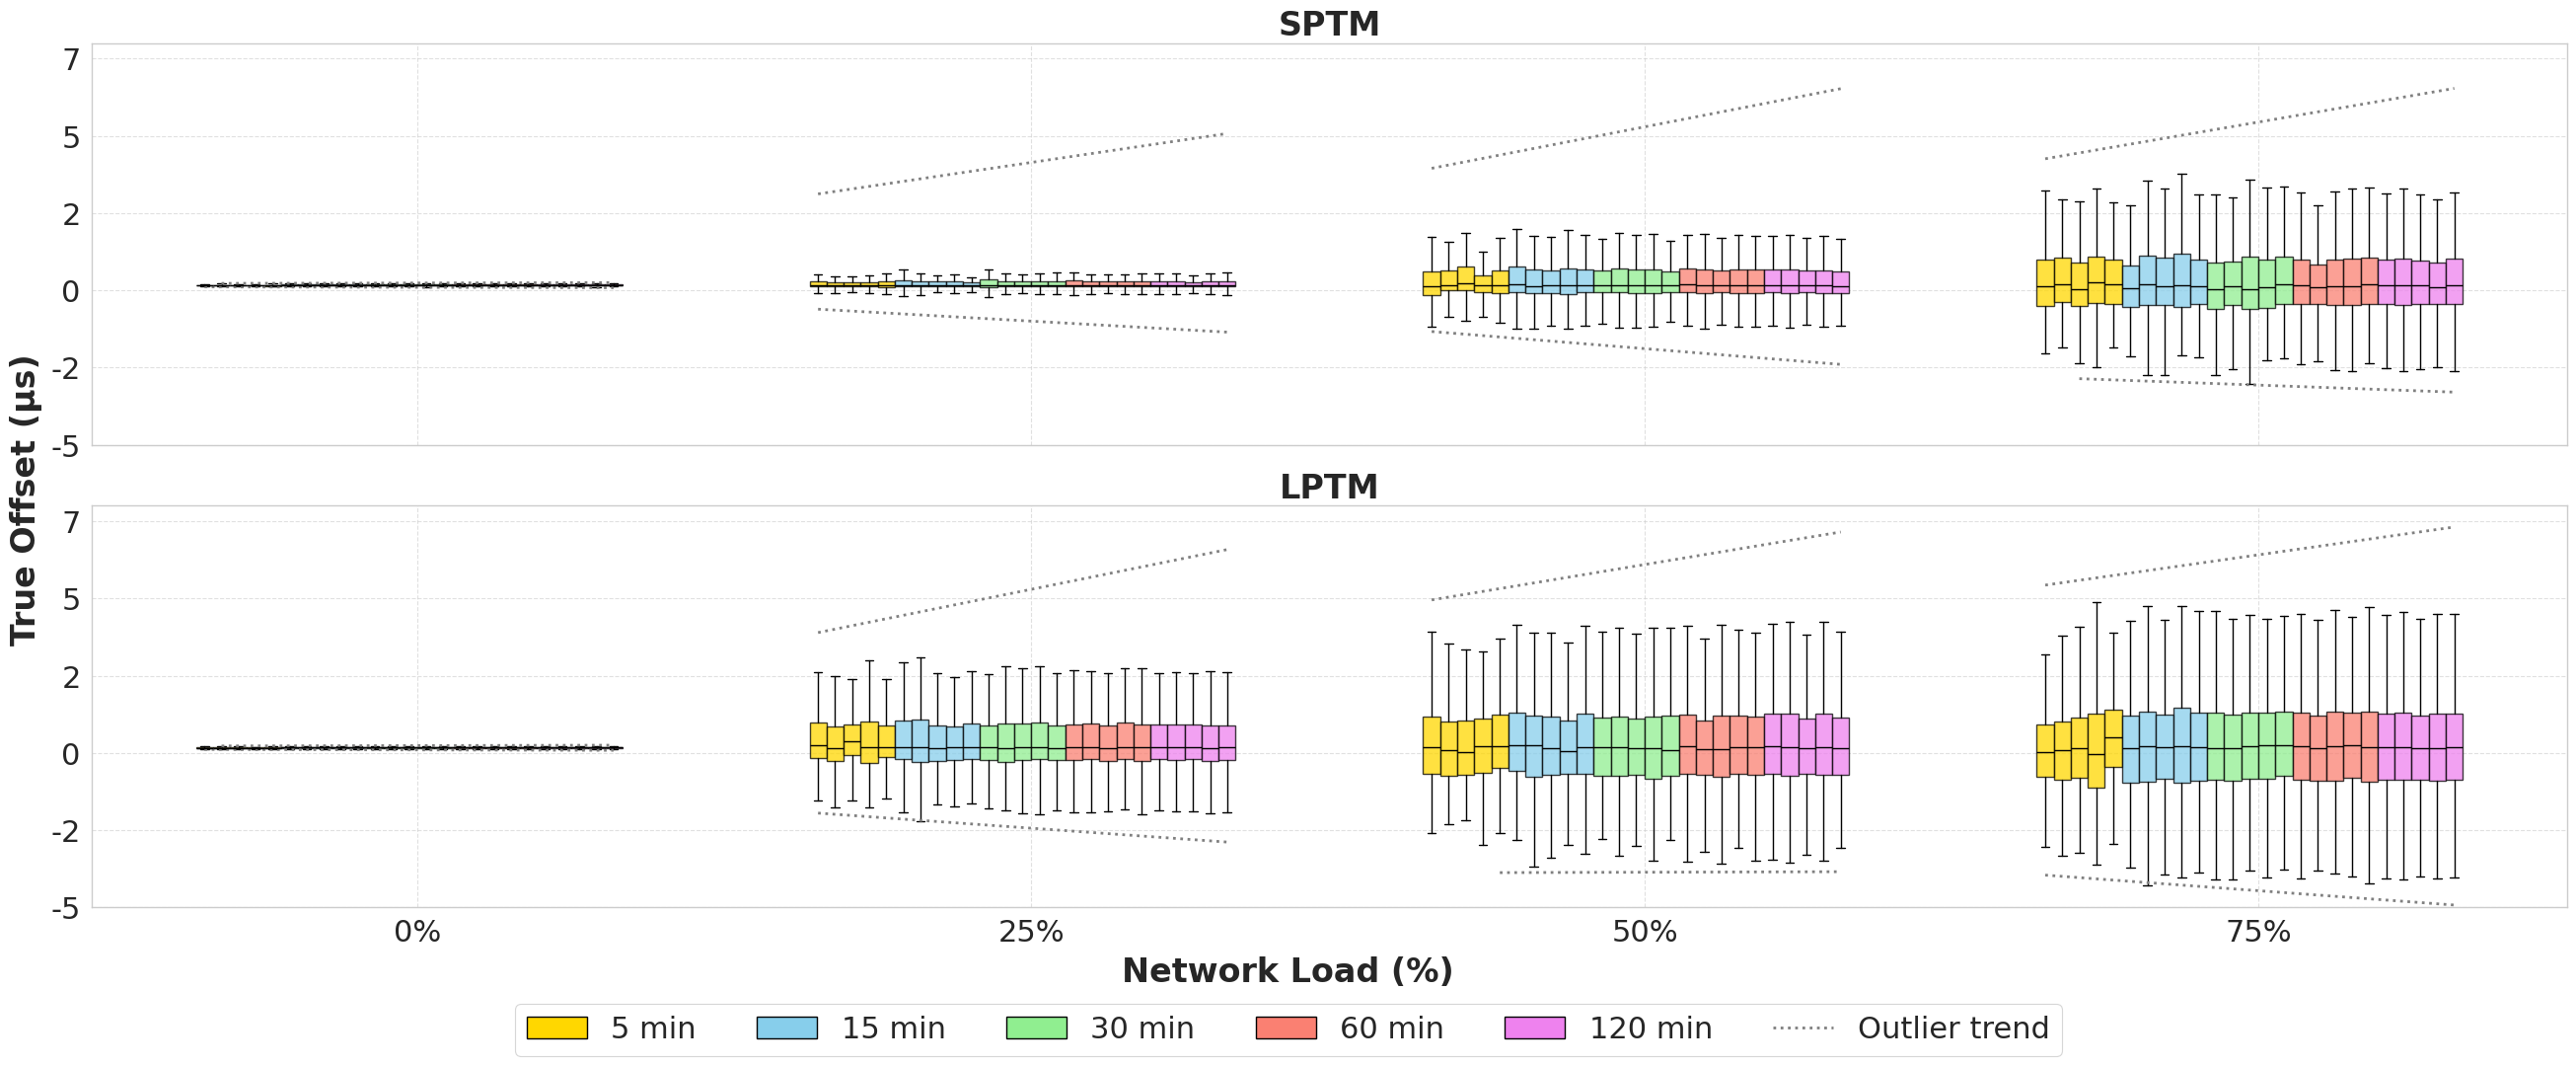

In [6]:

def plot_two_models_vertical(
    datasets_SPTM,
    datasets_LPTM,
    client: str,
    time_cols,
    load_labels,
    labels=("SPTM", "LPTM"),
    filename="example.pdf"
):
    fig, axes = plt.subplots(2, 1, figsize=(26, 10), sharex=True, constrained_layout=True)

    # Arriba
    handles1, labels1 = plotBoxplotWithLoadLevels(
        datasets_SPTM,
        client=client,
        time_cols=time_cols,
        load_labels=load_labels,
        traffic_model=labels[0],
        ax=axes[0]
    )

    # Abajo
    handles2, labels2 = plotBoxplotWithLoadLevels(
        datasets_LPTM,
        client=client,
        time_cols=time_cols,
        load_labels=load_labels,
        traffic_model=labels[1],
        ax=axes[1]
    )

    
    final_handles = handles1
    final_labels = labels1
    
    fig.legend(
        final_handles,
        final_labels,
        loc="lower center",
        ncols=len(final_handles),   # horizontal
        fontsize=22,
        frameon=True,
        bbox_to_anchor=(0.5, -0.08)  # subirla un poco
    )

    fig.supxlabel("Network Load (%)", fontsize=24, fontweight='bold')
    fig.supylabel("True Offset (µs)", fontsize=24, fontweight='bold')
    #fig.suptitle("TimeStick Offset Distribution across Load Levels and Experiment Time", fontsize=24, fontweight='bold')
    #plt.title

    plt.savefig(filename, format="pdf", bbox_inches='tight', pad_inches=0.05)
    plt.show()

plot_two_models_vertical(
    all_datasets_SPTM,
    all_datasets_LPTM,
    client="TimeStick",
    time_cols=durations,
    load_labels=loads,
    filename="TimeStick_SPTMvsLPTM.pdf"
)

## Significance difference Heatmap by network load and experiment time

In [7]:
def bonferroni_correction(pvalues: List[float]) -> List[float]:
    n = len(pvalues)
    return [min(p * n, 1.0) for p in pvalues]       

def ks_comparisons_all_loads_matrix(
    all_datasets_by_load: List[List[List[pl.DataFrame]]],
    loads: List[int],
    durations: List[int],
    client: str,
) -> np.ndarray:
    n_durations = len(durations)
    n_loads = len(loads)
    result = np.full((n_durations, n_durations, n_loads), np.nan)

    for carga_idx, datasets_by_time in enumerate(all_datasets_by_load):
        for i in range(n_durations):
            base_reps = datasets_by_time[i]
            for j in range(i + 1, n_durations):  # Solo parte superior de la matriz
                comp_reps = datasets_by_time[j]
                p_values: List[float] = []
                for df_a in base_reps:
                    offsets_a = df_a.filter(pl.col("PTP_client") == client)["offset_hw_ns"].to_numpy()
                    for df_b in comp_reps:
                        offsets_b = df_b.filter(pl.col("PTP_client") == client)["offset_hw_ns"].to_numpy()
                        stat, pvalue = ks_2samp(offsets_a, offsets_b)
                        p_values.append(pvalue)

                corrected_p_values = bonferroni_correction(p_values)
                mean_pvalue = np.mean(corrected_p_values)
                result[i, j, carga_idx] = mean_pvalue

    return result



def plot_heatmaps(
    result: np.ndarray,
    loads: List[int],
    durations: List[int],
    filename = "example.pdf"
) -> None:
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    #fig.suptitle(f"Traffic Model {traffic_model}", fontsize=18)

    # Calcular vmin y vmax globales ignorando NaNs
    vmin = np.nanmin(result)
    vmax = np.nanmax(result)

    # Dibujar heatmaps sin barra individual
    for idx, ax in enumerate(axes.flat):
        sns.heatmap(
            result[:, :, idx],
            xticklabels=durations,
            yticklabels=durations,
            cmap="viridis",
            annot=True,
            fmt=".2f",
            cbar=False,
            ax=ax,
            mask=np.isnan(result[:, :, idx]),
            vmin=vmin,
            vmax=vmax,
            annot_kws={"fontsize": 20},
        )
        ax.set_title(f"{loads[idx]}%", fontsize=20, fontweight="bold")

        # Ocultar ticks innecesarios
        if idx < 2:  # fila superior
            ax.set_xticklabels([], fontsize=20)
        if idx % 2 == 1:  # columna derecha
            ax.set_yticklabels([], fontsize=20)
    
        ax.tick_params(axis='x', labelsize=22)
        ax.tick_params(axis='y', labelsize=22)
    
    # Etiquetas globales para los ejes
    fig.text(0.5, -0.02, "Duration (min)", ha="center", fontsize=24, fontweight='bold' )
    fig.text(-0.02, 0.5, "Duration (min)", va="center", rotation="vertical", fontsize=24, fontweight='bold')

    # Barra de color común
    cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label("Mean p-value", fontsize=24)
    cbar.ax.tick_params(labelsize=20)
    
    plt.tight_layout(rect=[0, 0, 0.9, 0.96])
    plt.savefig(filename, format="pdf", bbox_inches='tight')
    
    plt.show()


/tmp/ipykernel_594733/2112516438.py:89: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 0.96])


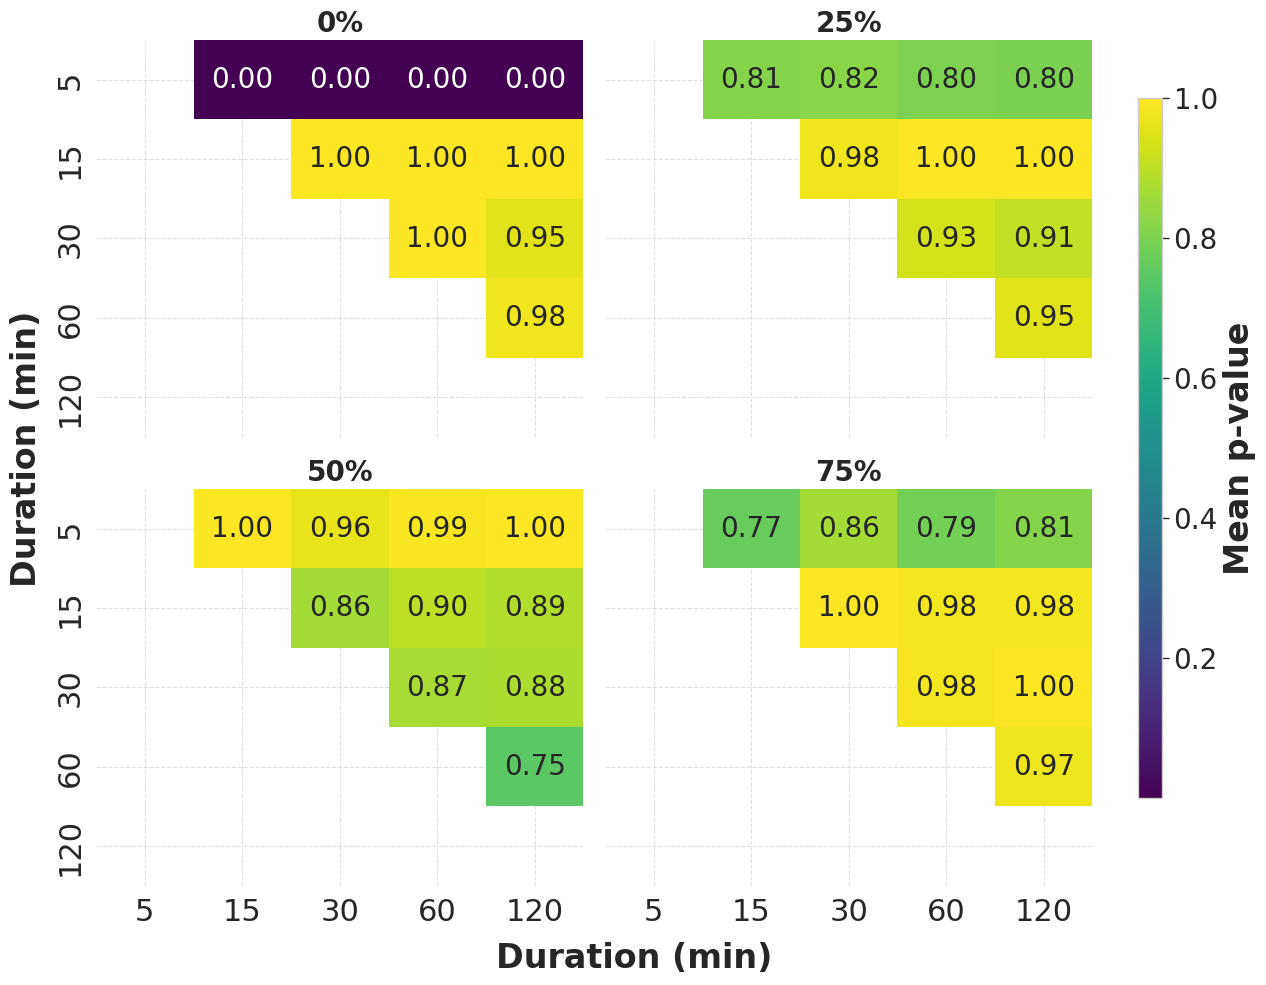

In [8]:

matrix_TimeStick_LPTM = ks_comparisons_all_loads_matrix(
    all_datasets_by_load=all_datasets_LPTM,
    loads=loads,
    durations=durations,
    client="TimeStick"
)

plot_heatmaps(matrix_TimeStick_LPTM, loads, durations, filename="TimeStick_LPTMKSHeatmap.pdf")